## Middleware

Middleware provides a way to more tightly control what happens inside the agent. Middleware is useful for the following:

1) Tracking agent behavior with logging, analytics, and debugging.
2) Transforming prompts, tool selection, and output formatting.
3) Adding retries, fallbacks, and early termination logic.
4) Applying rate limits, guardrails, and PII detection.

In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ["GROQ_API_KEY"] = os.getenv("Groq_API_KEY")

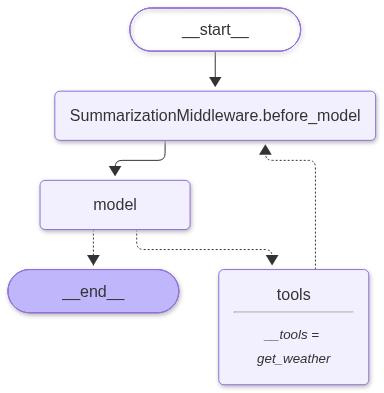

In [ ]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq
from langchain.agents.middleware import SummarizationMiddleware
from langchain.tools import tool
from langchain.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver

@tool
def get_weather(city:str) -> str:
    """Get the weather of the city"""
    return f"The weather is Sunny in {city} today."


llm = ChatGroq(
    model = "openai/gpt-oss-20b",
    temperature= 0
)

summary_llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

agent = create_agent(
    model = llm, 
    checkpointer = InMemorySaver,
    middleware = [
        SummarizationMiddleware(
            model = summary_llm,
            trigger = ("messages", 10),
            keep = ("messages", 4)
        )
    ]
)

agent

In [18]:
confiq = {
    "confiqurable" : 
        {"thread_id": "test-1"}
}


questions = [
    "What is 2+2 ?",
    "What is 2-2 ?",
    "What is 2*2 ?",
    "What is 2/2 ?",
    "What is 12*2 ?",
    "What is 2/22 ?",
    "What is 24*2 ?",
    "What is 100/4 ?",
]


for question in questions: 
    response = agent.invoke({"messages":[HumanMessage(content=question)]}, confiq)
    print(response["messages"][-1].content)
    print("Length of Message", len(response["messages"]))

2 + 2 = 4.
Length of Message 2
2 − 2 = 0.
Length of Message 2
2 × 2 = 4.
Length of Message 2
2 ÷ 2 equals **1**.
Length of Message 2
12 × 2 = 24.
Length of Message 2
\( \displaystyle \frac{2}{22} = \frac{1}{11} \approx 0.0909\) (repeating).
Length of Message 2
24 × 2 = 48.
Length of Message 2
100 ÷ 4 = **25**
Length of Message 2
